# Caracterización de las veredas Paso Chico, Los Teres y La Laguna
**Municipio de Los Santos, Santander · Censo poblacional (Sisbén IV)**

## Pregunta
Caracterizar a las veredas de Paso Chico, Los Teres y La Laguna a partir de los datos del censo de población.

## Enfoque de este análisis
En lugar de recorrer variable por variable, se responden cuatro preguntas y se construyen dos herramientas propias:

| Sección | Pregunta | Herramienta |
|---|---|---|
| 3 | ¿Quiénes viven en cada vereda? | Pirámides de población y tabla de indicadores |
| 4 | ¿Qué les falta? | **Índice de carencias del hogar (ICH)**, de 0 a 8 |
| 5 | ¿Qué tipos de hogar hay? | **Tipología de hogares** |
| 6 | ¿De qué viven y cuánto gastan? | Gasto por persona y peso de la comida |
| 7 | ¿Qué diferencias son reales? | Pruebas estadísticas |
| 8 | Conclusiones y limitaciones | |

**Reglas de comparación:** siempre porcentajes y medianas (nunca conteos, porque las veredas tienen tamaños muy distintos); Laguna Alta (52 hogares) y Los Teres (66) son pequeñas, así que solo las diferencias grandes son concluyentes.

## 1. Configuración y carga de datos

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Ruta del archivo en Google Drive (si no usas Colab, cambia RUTA por la ruta local del Excel)
RUTA = '/content/drive/MyDrive/CENSO POBLACIONAL AGOSTO.xlsx'

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass   # fuera de Colab no hace falta montar Drive

censo = pd.read_excel(RUTA)
print('Registros del municipio:', censo.shape[0], '| columnas:', censo.shape[1])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Registros del municipio: 12987 | columnas: 255


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Preparación de los datos

- Se filtran las cuatro unidades de estudio (en la base: `PASOCHICO`, `LOS TERES`, `LAGUNA ALTA`, `LAGUNA BAJA`).
- Cada fila es una **persona**. El **hogar** se identifica con `num_ficha` + `ide_hogar`.
- Las variables del hogar se analizan con una fila por hogar (`hogares`) y las de las personas con una fila por persona (`personas`).

In [10]:
NOMBRES = {'PASOCHICO': 'Paso Chico', 'LOS TERES': 'Los Teres',
           'LAGUNA ALTA': 'Laguna Alta', 'LAGUNA BAJA': 'Laguna Baja'}
ORDEN = list(NOMBRES.values())
COLOR = {'Paso Chico': '#2f7d6d', 'Los Teres': '#c8553d', 'Laguna Alta': '#e0a53a', 'Laguna Baja': '#4a6fa5'}

personas = censo[censo['NOM_VEREDA'].isin(NOMBRES)].copy()
personas['vereda'] = personas['NOM_VEREDA'].map(NOMBRES)
personas['id_hogar'] = personas['num_ficha'].astype(str) + '-' + personas['ide_hogar'].astype(str)

hogares = personas.drop_duplicates('id_hogar').copy()

print('Personas:', len(personas), '| Hogares:', len(hogares), '| Viviendas:', personas['num_ficha'].nunique())
print('\nPersonas por vereda:'); print(personas['vereda'].value_counts().reindex(ORDEN))
print('\nHogares por vereda:');  print(hogares['vereda'].value_counts().reindex(ORDEN))

Personas: 1108 | Hogares: 386 | Viviendas: 324

Personas por vereda:
vereda
Paso Chico     258
Los Teres      214
Laguna Alta    119
Laguna Baja    517
Name: count, dtype: int64

Hogares por vereda:
vereda
Paso Chico      90
Los Teres       66
Laguna Alta     52
Laguna Baja    178
Name: count, dtype: int64


### 2.1 Variables que se agregan al hogar
A partir de los datos de las personas se calculan, para cada hogar: ingreso total, subsidios, edades, número de niños y de mayores, y el mayor nivel educativo de sus adultos.

Códigos usados (ficha Sisbén IV): `niv_educativo` 4 = media (bachillerato); `tip_mat_pisos` 5 = tierra; `tip_origen_agua` 4 = pozo sin bomba/aljibe, 5 = agua lluvia, 6 = río o quebrada; `tip_energia_cocina` 6 = leña; `tip_sanitario` 3 = inodoro sin conexión, 4 = letrina, 5 = no tiene; `tip_seg_social` 3 = subsidiado; `ind_tiene_nevera` 2 = no.

In [11]:
INGRESOS = ['vlr_ingr_salario', 'vlr_ingr_honorarios', 'vlr_ingr_cosecha', 'vlr_ingr_pension',
            'vlr_ingr_remesa_pais', 'vlr_ingr_fam_accion', 'vlr_ingr_col_mayor', 'vlr_ingr_otro_subsidio']
SUBSIDIOS = ['vlr_ingr_fam_accion', 'vlr_ingr_col_mayor', 'vlr_ingr_otro_subsidio']

g = personas.groupby('id_hogar')
hogares['ingreso']    = hogares['id_hogar'].map(g[INGRESOS].sum().sum(axis=1))
hogares['subsidio']   = hogares['id_hogar'].map(g[SUBSIDIOS].sum().sum(axis=1))
hogares['n_ninos']    = hogares['id_hogar'].map(g['edad_calculada'].apply(lambda s: (s < 15).sum()))
hogares['n_mayores']  = hogares['id_hogar'].map(g['edad_calculada'].apply(lambda s: (s >= 60).sum()))
hogares['max_niv_adulto'] = hogares['id_hogar'].map(
    g.apply(lambda x: x.loc[x['edad_calculada'] >= 18, 'niv_educativo'].max()))
hogares['n'] = hogares['num_personas_hogar']

# Gasto por persona y parte del gasto en alimentos
hogares['gasto_pc'] = hogares['vlr_total_gastos'] / hogares['n']
hogares['pct_alimentos'] = hogares['vlr_gasto_alimento'] / hogares['vlr_total_gastos'].replace(0, np.nan) * 100

# Pobreza según Sisbén (grupos A y B) y eventos (inundación, avalancha, terremoto, incendio, vendaval, hundimiento)
hogares['sisben_AB'] = hogares['Grupo'].isin(['A', 'B'])
hogares['evento'] = (hogares[[c for c in hogares.columns if c.startswith('ind_evento_')]] == 1).any(axis=1)

# Jefe(a) del hogar
jefes = personas[personas['tip_parentesco'] == 1].drop_duplicates('id_hogar')
hogares['jefa_mujer'] = hogares['id_hogar'].isin(jefes.loc[jefes['sexo_persona'] == 2, 'id_hogar'])
print('Hogares con exactamente un jefe:', (personas[personas.tip_parentesco == 1].groupby('id_hogar').size() == 1).sum(), 'de', len(hogares))

Hogares con exactamente un jefe: 386 de 386


/tmp/ipykernel_854/4173737977.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  g.apply(lambda x: x.loc[x['edad_calculada'] >= 18, 'niv_educativo'].max()))


## 3. ¿Quiénes viven en cada vereda?
### 3.1 Pirámides de población

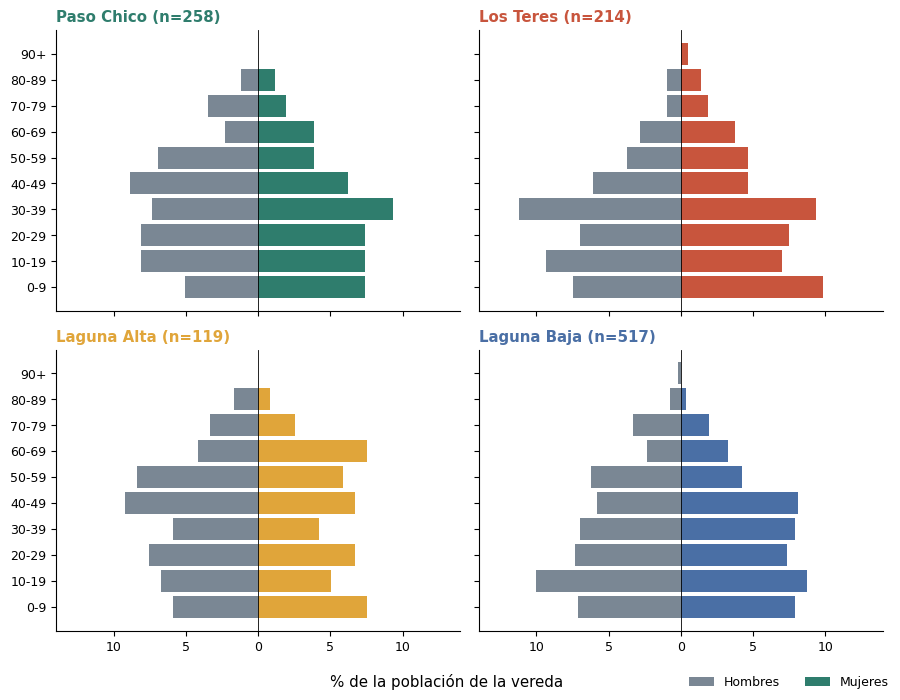

In [12]:
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})

cortes = list(range(0, 100, 10))
etiquetas = [f'{c}-{c+9}' for c in cortes[:-1]] + ['90+']

fig, axs = plt.subplots(2, 2, figsize=(9, 7), sharex=True, sharey=True)
for ax, vereda in zip(axs.flat, ORDEN):
    d = personas[personas['vereda'] == vereda]
    grupo_edad = pd.cut(d['edad_calculada'].clip(upper=95), cortes + [200], right=False, labels=etiquetas)
    hombres = d[d['sexo_persona'] == 1].groupby(grupo_edad, observed=False).size() / len(d) * 100
    mujeres = d[d['sexo_persona'] == 2].groupby(grupo_edad, observed=False).size() / len(d) * 100
    y = np.arange(len(etiquetas))
    ax.barh(y, -hombres.values, color='#7a8794', height=.85, label='Hombres')
    ax.barh(y, mujeres.values, color=COLOR[vereda], height=.85, label='Mujeres')
    ax.set_yticks(y, etiquetas)
    ax.set_title(f'{vereda} (n={len(d)})', loc='left', color=COLOR[vereda], fontweight='bold')
    ax.axvline(0, color='k', lw=.6); ax.set_xlim(-14, 14)
    ax.set_xticks([-10, -5, 0, 5, 10], ['10', '5', '0', '5', '10'])
fig.supxlabel('% de la población de la vereda')
h_, l_ = axs[0, 0].get_legend_handles_labels()
fig.legend(h_, l_, frameon=False, loc='lower right', ncol=2)
plt.tight_layout(); plt.show()

**Lectura:** Los Teres es la más joven; Laguna Alta es la más envejecida (base más estrecha y más personas de 60 y más); Paso Chico concentra población en edad de trabajar; Laguna Baja queda en el punto medio.

### 3.2 Tabla de indicadores de población, educación y salud
- **Razón de dependencia:** personas menores de 15 y de 65 o más por cada 100 de 15 a 64 años.
- **Analfabetismo:** sobre personas de 15 años o más. **Bachillerato o más:** sobre personas de 25 años o más.

In [13]:
def indicadores_personas(d):
    edad = d['edad_calculada']
    de15, de25 = d[edad >= 15], d[edad >= 25]
    discap = [c for c in d.columns if c.startswith('ind_discap_') and c != 'ind_discap_ninguna']
    return pd.Series({
        'Personas': len(d),
        'Mujeres (%)': (d['sexo_persona'] == 2).mean() * 100,
        'Edad mediana (años)': edad.median(),
        'Menores de 15 (%)': (edad < 15).mean() * 100,
        'Mayores de 60 (%)': (edad >= 60).mean() * 100,
        'Razón de dependencia': ((edad < 15).sum() + (edad >= 65).sum()) / ((edad >= 15) & (edad < 65)).sum() * 100,
        'Analfabetismo, 15+ (%)': (de15['ind_leer_escribir'] == 2).mean() * 100,
        'Bachillerato o más, 25+ (%)': (de25['niv_educativo'] >= 4).mean() * 100,
        'Régimen subsidiado (%)': (d['tip_seg_social'] == 3).mean() * 100,
        'Con alguna discapacidad (%)': (d[discap] == 1).any(axis=1).mean() * 100,
        'Trabajaba el último mes, 15+ (%)': (de15['tip_actividad_mes'] == 1).mean() * 100,
    })

tabla_personas = pd.DataFrame({v: indicadores_personas(personas[personas['vereda'] == v]) for v in ORDEN})
tabla_personas['Total'] = indicadores_personas(personas)
tabla_personas.round(1)

,Paso Chico,Los Teres,Laguna Alta,Laguna Baja,Total
Personas,258.0,214.0,119.0,517.0,1108.0
Mujeres (%),48.4,50.5,47.1,49.9,49.4
Edad mediana (años),34.0,30.0,40.0,31.0,32.0
Menores de 15 (%),18.6,27.6,20.2,23.0,22.6
Mayores de 60 (%),14.0,12.1,20.2,12.2,13.4
Razón de dependencia,41.0,56.2,50.6,48.1,48.1
"Analfabetismo, 15+ (%)",8.1,9.0,13.7,7.3,8.5
"Bachillerato o más, 25+ (%)",24.4,13.6,17.7,23.6,21.2
Régimen subsidiado (%),65.9,54.2,63.0,56.7,59.0
Con alguna discapacidad (%),3.9,4.7,8.4,3.3,4.2


**Lectura:** la educación se divide en dos pares: Paso Chico y Laguna Baja tienen cerca del 24 % de adultos con bachillerato, mientras que Los Teres tiene solo el 13,6 %. Laguna Alta concentra el mayor analfabetismo y la mayor discapacidad, pero con pocos casos (unas 10 personas con discapacidad), así que esa cifra debe leerse con cautela.

## 4. ¿Qué les falta? El índice de carencias del hogar (ICH)

El ICH suma **8 carencias**; cada hogar recibe 1 punto por cada una que tiene:

1. Piso de tierra.
2. Sin inodoro conectado (inodoro sin conexión, letrina o sin sanitario).
3. Agua de lluvia, aljibe o río como origen principal.
4. Cocina con leña.
5. Hacinamiento: 3 o más personas por cuarto para dormir.
6. Sin nevera.
7. Sin ingresos declarados (la suma de los ingresos de todos los miembros es cero).
8. Ningún adulto (18 años o más) con bachillerato.

Niveles: **baja** (0 a 2), **media** (3 a 4) y **alta** (5 a 8). Es una medida propia de este trabajo, no un indicador oficial, y todas las carencias pesan igual.

In [14]:
carencias = pd.DataFrame(index=hogares.index)
carencias['Piso de tierra']                   = hogares['tip_mat_pisos'] == 5
carencias['Sin inodoro conectado']            = hogares['tip_sanitario'].isin([3, 4, 5])
carencias['Agua de lluvia, aljibe o río']     = hogares['tip_origen_agua'].isin([4, 5, 6])
carencias['Cocina con leña']                  = hogares['tip_energia_cocina'] == 6
carencias['Hacinamiento (3+ por cuarto)']     = hogares['n'] / hogares['num_cuartos_dormir'].clip(lower=1) >= 3
carencias['Sin nevera']                       = hogares['ind_tiene_nevera'] == 2
carencias['Sin ingresos declarados']          = hogares['ingreso'] == 0
carencias['Ningún adulto con bachillerato']   = ~(hogares['max_niv_adulto'] >= 4)

hogares['ICH'] = carencias.sum(axis=1)
hogares['nivel'] = pd.cut(hogares['ICH'], [-1, 2, 4, 9], labels=['Baja (0-2)', 'Media (3-4)', 'Alta (5-8)'])

print('Distribución del ICH (n.º de carencias → hogares):')
print(hogares['ICH'].value_counts().sort_index().to_dict())

Distribución del ICH (n.º de carencias → hogares):
{0: 1, 1: 11, 2: 51, 3: 81, 4: 93, 5: 78, 6: 54, 7: 16, 8: 1}


### 4.1 Porcentaje de hogares con cada carencia

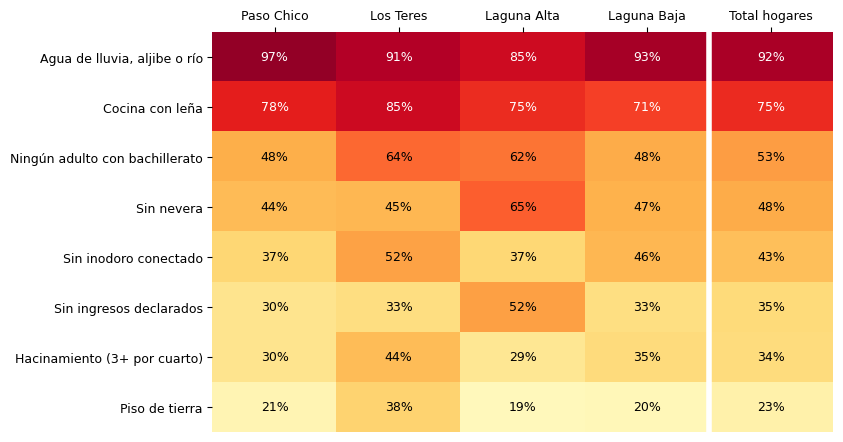

In [15]:
mapa = pd.concat([carencias.groupby(hogares['vereda']).mean().mul(100).reindex(ORDEN).T,
                  carencias.mean().mul(100).rename('Total hogares')], axis=1)
mapa = mapa.sort_values('Total hogares', ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.imshow(mapa.values, cmap='YlOrRd', vmin=15, vmax=100, aspect='auto')
ax.set_xticks(range(mapa.shape[1]), mapa.columns); ax.set_yticks(range(len(mapa)), mapa.index)
ax.xaxis.tick_top(); [s.set_visible(False) for s in ax.spines.values()]
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        ax.text(j, i, f'{mapa.values[i, j]:.0f}%', ha='center', va='center',
                color='white' if mapa.values[i, j] > 70 else 'black')
ax.axvline(3.5, color='white', lw=4)
plt.tight_layout(); plt.show()

**Lectura:**
- Hay carencias **de toda la zona** que no distinguen entre veredas: el agua (85 % a 97 %) y la cocina con leña (71 % a 85 %).
- Otras sí diferencian: Los Teres lidera piso de tierra (38 %, casi el doble que las demás), sanitario sin conexión (52 %) y hacinamiento (44 %). Laguna Alta sobresale en sin nevera (65 %) y sin ingresos declarados (52 %).

### 4.2 Nivel de carencia por vereda

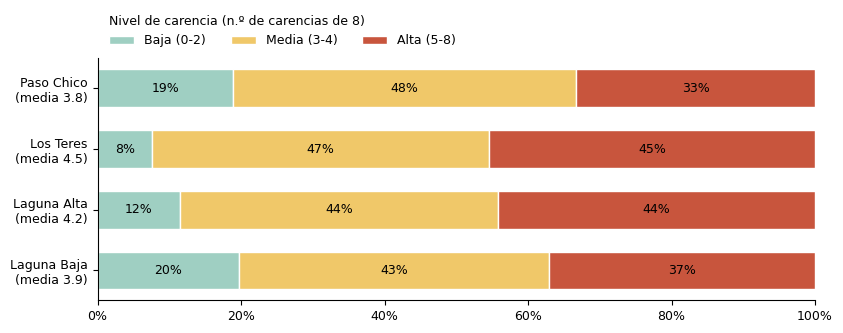

ICH promedio total: 4.05


In [16]:
niveles = pd.crosstab(hogares['vereda'], hogares['nivel'], normalize='index').mul(100).reindex(ORDEN)
media_ich = hogares.groupby('vereda')['ICH'].mean().reindex(ORDEN)

fig, ax = plt.subplots(figsize=(8.5, 3.4))
izq = np.zeros(len(ORDEN))
for col, color in zip(niveles.columns, ['#9fcfc2', '#f0c869', '#c8553d']):
    ax.barh(range(len(ORDEN)), niveles[col], left=izq, color=color, edgecolor='white', height=.62, label=col)
    for i, (l, w) in enumerate(zip(izq, niveles[col])):
        ax.text(l + w / 2, i, f'{w:.0f}%', ha='center', va='center')
    izq += niveles[col].values
ax.set_yticks(range(len(ORDEN)), [f'{v}\n(media {media_ich[v]:.1f})' for v in ORDEN]); ax.invert_yaxis()
ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0f}%')
ax.legend(ncol=3, frameon=False, loc='lower left', bbox_to_anchor=(0, 1), title='Nivel de carencia (n.º de carencias de 8)', alignment='left')
plt.tight_layout(); plt.show()
print('ICH promedio total:', round(hogares['ICH'].mean(), 2))

### 4.3 ¿El índice mide algo real?
Se contrasta con el grupo del Sisbén (A y B = pobreza): si el índice es útil, los hogares con muchas carencias deben estar más en A y B.

In [17]:
alta = hogares['ICH'] >= 5
print(f"Hogares con 5+ carencias en Sisbén A o B:  {hogares.loc[alta, 'sisben_AB'].mean() * 100:.0f} %")
print(f"Hogares con menos de 5 carencias en A o B: {hogares.loc[~alta, 'sisben_AB'].mean() * 100:.0f} %")
rho, p = stats.spearmanr(hogares['ICH'], hogares['gasto_pc'])
print(f"\nCorrelación (Spearman) entre ICH y gasto por persona: {rho:.2f} (p = {p:.3f})")

Hogares con 5+ carencias en Sisbén A o B:  80 %
Hogares con menos de 5 carencias en A o B: 61 %

Correlación (Spearman) entre ICH y gasto por persona: -0.29 (p = 0.000)


## 5. ¿Qué tipos de hogar hay?

Cada hogar se asigna a **un solo tipo**, en este orden: *unipersonal*; *con niños* (alguien menor de 15 años); *adultos con un mayor de 60*; y *solo adultos*.

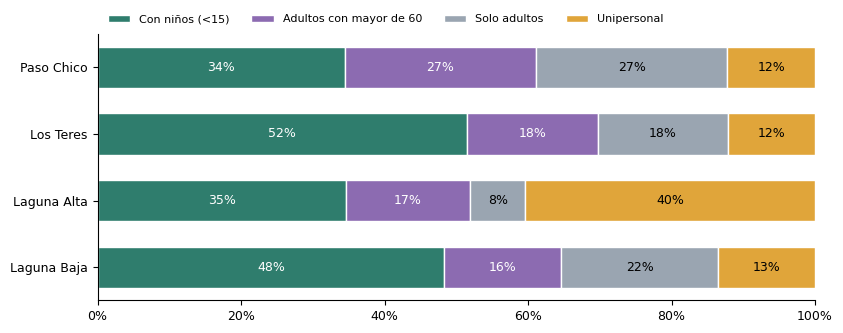

In [18]:
def tipo_hogar(h):
    if h['n'] == 1:        return 'Unipersonal'
    if h['n_ninos'] > 0:   return 'Con niños (<15)'
    if h['n_mayores'] > 0: return 'Adultos con mayor de 60'
    return 'Solo adultos'

hogares['tipo'] = hogares.apply(tipo_hogar, axis=1)
TIPOS = ['Con niños (<15)', 'Adultos con mayor de 60', 'Solo adultos', 'Unipersonal']

tipos = pd.crosstab(hogares['vereda'], hogares['tipo'], normalize='index').mul(100).reindex(ORDEN)[TIPOS]

fig, ax = plt.subplots(figsize=(8.5, 3.4))
izq = np.zeros(len(ORDEN))
for col, color in zip(TIPOS, ['#2f7d6d', '#8c6bb1', '#9aa5b1', '#e0a53a']):
    ax.barh(range(len(ORDEN)), tipos[col], left=izq, color=color, edgecolor='white', height=.62, label=col)
    for i, (l, w) in enumerate(zip(izq, tipos[col])):
        if w >= 5: ax.text(l + w / 2, i, f'{w:.0f}%', ha='center', va='center', color='white' if color in ['#2f7d6d', '#8c6bb1'] else 'black')
    izq += tipos[col].values
ax.set_yticks(range(len(ORDEN)), ORDEN); ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0f}%')
ax.legend(ncol=4, frameon=False, loc='lower left', bbox_to_anchor=(0, 1), fontsize=8)
plt.tight_layout(); plt.show()

In [19]:
por_tipo = hogares.groupby('tipo').agg(hogares=('ICH', 'size'),
                                       carencias_promedio=('ICH', 'mean'),
                                       sisben_AB_pct=('sisben_AB', lambda s: s.mean() * 100)).reindex(TIPOS)
por_tipo.round(1)

,hogares,carencias_promedio,sisben_AB_pct
tipo,,,
Con niños (<15),169,4.0,69.2
Adultos con mayor de 60,74,3.9,75.7
Solo adultos,79,3.9,55.7
Unipersonal,64,4.6,71.9


**Lectura:** en Los Teres y Laguna Baja predominan los hogares con niños; en Laguna Alta casi 4 de cada 10 hogares son de una sola persona. Los hogares unipersonales son los que más carencias acumulan.

## 6. ¿De qué viven y cuánto gastan?

Los ingresos están **subdeclarados**, así que la capacidad económica se compara con el **gasto** (mediana por vereda).

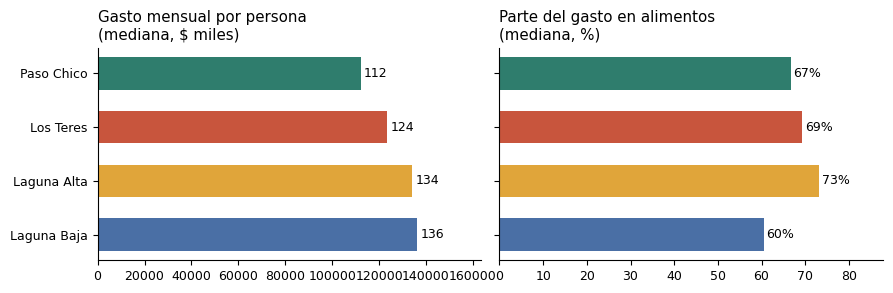

,gasto_hogar_mediano,gasto_por_persona_mediano,pct_gasto_en_alimentos,sin_ingresos_pct,con_subsidio_pct
vereda,,,,,
Paso Chico,317500.0,112250.0,66.7,30.0,42.2
Los Teres,348000.0,123583.3,69.3,33.3,40.9
Laguna Alta,270000.0,134166.7,73.2,51.9,34.6
Laguna Baja,410000.0,136250.0,60.5,33.1,44.9


In [20]:
resumen_gasto = hogares.groupby('vereda').agg(
    gasto_hogar_mediano=('vlr_total_gastos', 'median'),
    gasto_por_persona_mediano=('gasto_pc', 'median'),
    pct_gasto_en_alimentos=('pct_alimentos', 'median'),
    sin_ingresos_pct=('ingreso', lambda s: (s == 0).mean() * 100),
    con_subsidio_pct=('subsidio', lambda s: (s > 0).mean() * 100)).reindex(ORDEN)

fig, axs = plt.subplots(1, 2, figsize=(9, 3))
for ax, col, titulo, fmt in [(axs[0], 'gasto_por_persona_mediano', 'Gasto mensual por persona\n(mediana, $ miles)', lambda x: f'{x/1000:.0f}'),
                             (axs[1], 'pct_gasto_en_alimentos', 'Parte del gasto en alimentos\n(mediana, %)', lambda x: f'{x:.0f}%')]:
    valores = resumen_gasto[col]
    ax.barh(range(4), valores, color=[COLOR[v] for v in ORDEN], height=.6)
    for i, x in enumerate(valores): ax.text(x * 1.01, i, fmt(x), va='center')
    ax.set_yticks(range(4), ORDEN if ax is axs[0] else [''] * 4); ax.invert_yaxis()
    ax.set_title(titulo, loc='left'); ax.set_xlim(0, valores.max() * 1.2)
plt.tight_layout(); plt.show()
resumen_gasto.round(1)

**Lectura:** el gasto por persona es parecido entre veredas, pero el **gasto total del hogar** sí varía (menor en Laguna Alta, mayor en Laguna Baja). En Laguna Alta el gasto por persona se sostiene porque los hogares son pequeños, no porque haya más recursos; además allí la comida pesa más en el gasto.

### 6.1 Tabla de indicadores de hogar

In [21]:
def indicadores_hogar(d):
    return pd.Series({
        'Hogares': len(d),
        'Tamaño medio del hogar': d['n'].mean(),
        'Jefatura femenina (%)': d['jefa_mujer'].mean() * 100,
        'Carencias (promedio de 8)': d['ICH'].mean(),
        'Hogares con 5+ carencias (%)': (d['ICH'] >= 5).mean() * 100,
        'Hogares unipersonales (%)': (d['tipo'] == 'Unipersonal').mean() * 100,
        'Sin ingresos declarados (%)': (d['ingreso'] == 0).mean() * 100,
        'Con algún subsidio (%)': (d['subsidio'] > 0).mean() * 100,
        'Vivienda propia (%)': d['tip_ocupa_vivienda'].isin([2, 3]).mean() * 100,
        'Sisbén A+B (%)': d['sisben_AB'].mean() * 100,
        'Afectados por un evento (%)': d['evento'].mean() * 100,
    })

tabla_hogares = pd.DataFrame({v: indicadores_hogar(hogares[hogares['vereda'] == v]) for v in ORDEN})
tabla_hogares['Total'] = indicadores_hogar(hogares)
tabla_hogares.round(1)

,Paso Chico,Los Teres,Laguna Alta,Laguna Baja,Total
Hogares,90.0,66.0,52.0,178.0,386.0
Tamaño medio del hogar,2.9,3.2,2.3,2.9,2.9
Jefatura femenina (%),36.7,50.0,51.9,41.0,43.0
Carencias (promedio de 8),3.8,4.5,4.2,3.9,4.0
Hogares con 5+ carencias (%),33.3,45.5,44.2,37.1,38.6
Hogares unipersonales (%),12.2,12.1,40.4,13.5,16.6
Sin ingresos declarados (%),30.0,33.3,51.9,33.1,35.0
Con algún subsidio (%),42.2,40.9,34.6,44.9,42.2
Vivienda propia (%),10.0,12.1,0.0,10.7,9.3
Sisbén A+B (%),63.3,71.2,69.2,69.1,68.1


## 7. ¿Qué diferencias son reales?

Con pocos hogares por vereda, una diferencia puede ser simple azar. Se prueba el ICH entre veredas:
- **Kruskal-Wallis:** ¿las cuatro veredas son iguales en carencias?
- **Mann-Whitney:** comparación por pares (sin corregir por comparaciones múltiples, así que es un indicio, no una prueba definitiva).

In [22]:
H, p = stats.kruskal(*[hogares.loc[hogares['vereda'] == v, 'ICH'] for v in ORDEN])
print(f'Kruskal-Wallis: H = {H:.2f}, p = {p:.3f}\n')

pares = []
for i, a in enumerate(ORDEN):
    for b in ORDEN[i + 1:]:
        u = stats.mannwhitneyu(hogares.loc[hogares['vereda'] == a, 'ICH'], hogares.loc[hogares['vereda'] == b, 'ICH'])
        pares.append({'Vereda A': a, 'Vereda B': b, 'p-valor': round(u.pvalue, 3),
                      '¿Diferencia clara (p < 0,05)?': 'Sí' if u.pvalue < 0.05 else 'No'})
pd.DataFrame(pares)

Kruskal-Wallis: H = 9.05, p = 0.029



,Vereda A,Vereda B,p-valor,"¿Diferencia clara (p < 0,05)?"
0,Paso Chico,Los Teres,0.010,Sí
1,Paso Chico,Laguna Alta,0.139,No
2,Paso Chico,Laguna Baja,0.697,No
3,Los Teres,Laguna Alta,0.353,No
4,Los Teres,Laguna Baja,0.011,Sí
5,Laguna Alta,Laguna Baja,0.183,No


**Lectura:** hay diferencias entre veredas (p ≈ 0,03), pero vienen sobre todo de **Los Teres frente a Paso Chico y a Laguna Baja** (p ≈ 0,01). Laguna Alta queda en el medio: con solo 52 hogares, su diferencia con las demás no es concluyente.

## 8. Fichas por vereda

**Paso Chico: la menos carente, pero sin agua segura** (258 personas, 90 hogares)
- La menor razón de dependencia (41) y la menor jefatura femenina (36,7 %).
- 24,4 % de los adultos con bachillerato o más, pero la mayor dependencia del régimen subsidiado (65,9 %).
- Promedio de 3,8 carencias (el más bajo), aunque el 97 % depende de agua de lluvia, aljibe o río.
- La menor pobreza Sisbén (63 %) y solo 8,9 % de hogares afectados por eventos.

**Los Teres: joven, con niños y las viviendas más precarias** (214 personas, 66 hogares)
- La más joven (mediana de 30 años) y con los hogares más grandes (3,2 personas); la mitad tiene jefa mujer.
- Solo 13,6 % de los adultos con bachillerato; en 64 % de los hogares ningún adulto lo logró.
- Promedio de 4,5 carencias (el más alto): lidera piso de tierra, sanitario sin conexión, hacinamiento y leña.
- La mayor pobreza Sisbén (71 %) y 18 % de hogares afectados por eventos.

**Laguna Alta: envejecida, con muchos hogares de una sola persona** (119 personas, 52 hogares)
- La mayor edad mediana (40 años), 20 % de mayores de 60 y 40 % de hogares unipersonales.
- El mayor analfabetismo (13,7 %) y la mayor discapacidad (8,4 %).
- 52 % de hogares sin ingresos declarados, el menor gasto del hogar y ninguna vivienda propia.
- La mayor afectación por eventos (29 %). Su pobreza Sisbén queda en el promedio, lo que contrasta con sus indicadores de ingreso y bienes.

**Laguna Baja: la más grande, cerca del promedio** (517 personas, 178 hogares)
- Casi la mitad de la población estudiada (47 %), por eso se parece al total.
- El menor analfabetismo (7,3 %) y la menor discapacidad (3,3 %).
- El mayor gasto del hogar y la menor parte del gasto en comida; más hogares con subsidio (45 %).
- El menor uso de leña (71 %), aunque 46 % sin sanitario conectado.

*Las cifras de esta sección se pueden verificar en las tablas de las secciones 3.2 y 6.1.*

## 9. Conclusiones

1. **Una pobreza compartida.** El agua de lluvia, aljibe o río y la cocina con leña afectan a casi todos los hogares sin importar la vereda. Las intervenciones en agua segura y cocinas mejoradas llegarían a toda la zona.
2. **Tres focos distintos.** Los Teres necesita mejoramiento de vivienda, saneamiento y educación para familias con niños. Laguna Alta requiere atención a personas mayores y que viven solas, y protección de ingresos. Paso Chico y Laguna Baja están algo mejor en lo material, pero con el mismo problema de agua.
3. **El tamaño y la composición del hogar importan.** Los hogares unipersonales acumulan más carencias que cualquier otro tipo, algo que no se ve al comparar solo promedios por vereda.

## 10. Limitaciones

- **Año del censo:** el enunciado habla de «censo 2024», pero las fechas de aplicación de la encuesta van de 2019 a diciembre de 2023. Conviene confirmar con la profesora cuál es la versión vigente.
- **Pocos casos:** Laguna Alta (52 hogares) y Los Teres (66) tienen pocos hogares; solo las diferencias grandes son concluyentes. La discapacidad y los eventos por desastre son aún más frágiles.
- **Ingresos subdeclarados:** se usa el gasto como aproximación, pero también es declarado.
- **Índice propio:** el ICH tiene pesos iguales; otras definiciones (por ejemplo, otro umbral de hacinamiento) podrían mover las posiciones entre veredas con diferencias pequeñas.
- **Pruebas por pares:** no se corrigieron por comparaciones múltiples.
- **Análisis descriptivo:** muestra diferencias entre veredas, no sus causas.